In [10]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
pil.FOLDER_DATA = pil.FOLDER_DATA_393
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import SimpleITK as sitk
import test_code.dfield_approach_elastix.constants as cts
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

np.set_printoptions(precision=4)


Important regions of the brain

lateral ventricles (R:43, L:4)
hipocampus (R:53, L:17)
talamus (R:49, L:10)
cortex (R:42, L:3)
    entorhinal cortex (R:2006, L:1006)
    inferior temporal gyri (R:2009, L:1009)
    superior parietal (R:2029, L:1029)
    middle frontal gyrus (R:2027, L:1027)
    superior frontal gyrus (R:2028, L:1028)
    precuneus (R:2025, L:1025)
    cuneus (R:2005, L:1005)

Other founds:
3rd ventricle (14)

In [11]:
IMPORTANT_TISSUES = [43, 4, 53, 17, 49, 10, 42, 3, 2006, 1006, 2009, 1009, 2029, 1029, 2027, 1027, 2028, 1028, 2025, 1025, 2005, 1005, 14]
print(len(IMPORTANT_TISSUES))

23


# Visualization

In [12]:
def visualize_voxplot(data, data_columns, nb_features=-1, nb_features_from=0, figsize=(20, 10)):
    if nb_features > 0:
        data = data[:, nb_features_from:nb_features_from+nb_features]
        data_columns = data_columns[nb_features_from:nb_features_from+nb_features]

    plt.figure(figsize=figsize)
    plt.boxplot(data, labels=data_columns)
    plt.title("Features")
    plt.plot()


def plot_correlation_heat_map(corr_matrix, figsize=(30, 30)):
    plt.figure(figsize=figsize)
    plt.imshow(corr_matrix, cmap='coolwarm')
    plt.colorbar()
    plt.title('Matriz de correlación')
    plt.show()



def plot_correlation_heat_map_df(corr_matrix_df, data_df, figsize=(30, 30)):

    plt.figure(figsize=figsize)
    sns.heatmap(corr_matrix_df, annot=True, cmap='coolwarm')
    plt.title('Correlation Matrix')
    plt.show()

    corr_matrix_df.values[[range(corr_matrix_df.shape[0])]*2] = 0

    pairs = []
    for row in range(corr_matrix_df.shape[0]):
        for col in range(row+1, corr_matrix_df.shape[1]):
            if abs(corr_matrix_df.iloc[row, col]) > 0.9:
                pairs.append((data_df.columns[row], data_df.columns[col]))


    for pair in pairs:
        plt.scatter(data_df[pair[0]], data_df[pair[1]])
        plt.xlabel(pair[0])
        plt.ylabel(pair[1])
        plt.title(f'Scatter Plot: {pair[0]} vs {pair[1]}')
        plt.show()


def plot_points(x, y, x_name, y_name):
    # Plotear los puntos
    plt.scatter(x, y)

    # Configurar el gráfico
    plt.xlabel(x_name)
    plt.ylabel(y_name)
    plt.title(f'{x_name} vs {y_name}')

    # Mostrar el gráfico
    plt.show()


def plot_2v2(data):
    for i in range(0, data.shape[1]):
        for j in range(i+1, data.shape[1]):
            plot_points(data[:, i], data[:, j], str(i), str(j))


def plot_2v2_df(data):
    columns = data.columns
    for i in range(0, len(columns)):
        for j in range(i+1, len(columns)):
            plot_points(data[columns[i]], data[columns[j]], columns[i], columns[j])

  

# Load data

In [28]:
class StatisticsReader:
    def __init__(self, path, name):
        self.path = path
        self.name = name

    def get_df(self, id_column="", ids=None):
        _df = self.__load_csv()
        if ids is not None:
            str_ids = [int("94100000{0}".format(id)) for id in ids]
            _df = _df[_df[id_column].isin(str_ids)]
        
        return _df

    def __load_csv(self):
        return pd.read_csv(f'{self.path}/{self.name}.csv')

   

# (not same patient) 01388: min: -1.0736, max: 4.6183, mean: 1.0000, std: 0.2147
# (same patient) 02408: min: -2.0260, max: 4.4923, mean: 1.0000, std: 0.1877
# (same patient) # 03139: min: -1.4722, max: 4.0456, mean: 1.0000, std: 0.0812
# (not same patient) 06611: min: -1.5924, max: 4.9465, mean: 1.0000, std: 0.1907
# (same patient) 02507: min: -0.7068, max: 3.6092, mean: 1.0000, std: 0.0665
remove_patients = ['01388', '06611', '02408', '03139', '02507']

In [39]:
satistics_results = f'{current_path}/data'
name = 'HAA_HUNT_summary_MRI_DTI_ok_HL'
reader = StatisticsReader(satistics_results, name)

matching_ids = pil.get_matching_ids()
data = reader.get_df("SubjID", matching_ids)
data = data.sort_values(by='SubjID')
# data_columns = data.columns.tolist()
display(data.shape)
display(data.head())

print(f"nuber of unique ages: {data['Age'].nunique()}")


# visualize_voxplot(data, data_columns, figsize=(50,10))

(301, 256)

,SubjID,VisitID,VisitNumber,StudyDate,MMPS_version,MMIL_Processing_Date,Sex,Age,Group,Site,...,CortContrastWhitectxrhcaudalmiddlefrontal,CortContrastWhitectxrhcorpuscallosum,CortContrastWhitectxrhcuneus,CortContrastWhitectxrhentorhinal,CortContrastWhitectxrhfusiform,CortContrastWhitectxrhinferiorparietal,CortContrastWhitectxrhinferiortemporal,CortContrastWhitectxrhisthmuscingulate,CortContrastWhitectxrhlateraloccipital,CortContrastWhitectxrhlateralorbitofrontal
8,9410000000039,9410000000039,1,19000101,225,26-Oct-2011,F,51,,HUNT,...,93.4901,121.1888,89.5995,94.7505,95.9306,96.3060,92.3841,104.4059,87.8722,91.7198
769,9410000000046,9410000000046,1,19000101,225,26-Oct-2011,M,63,,HUNT,...,89.5530,109.2180,83.6935,79.7070,86.0511,90.8724,83.0841,94.1982,83.4201,88.5160
544,9410000000053,9410000000053,1,19000101,225,26-Oct-2011,M,60,,HUNT,...,77.8755,88.3218,74.5077,64.4854,74.4769,80.1154,73.7721,78.2536,76.6607,74.8588
147,9410000000077,9410000000077,1,19000101,225,26-Oct-2011,F,54,,HUNT,...,84.5621,105.7476,84.1750,80.2314,88.0558,91.0058,86.0854,94.0066,85.1286,85.6214
289,9410000000091,9410000000091,1,19000101,225,26-Oct-2011,M,56,,HUNT,...,77.2036,96.4338,76.6101,70.9890,78.0744,83.2062,76.2892,83.7759,77.8517,77.4974


nuber of unique ages: 16


# Preprocessing

### Standarize and normalize

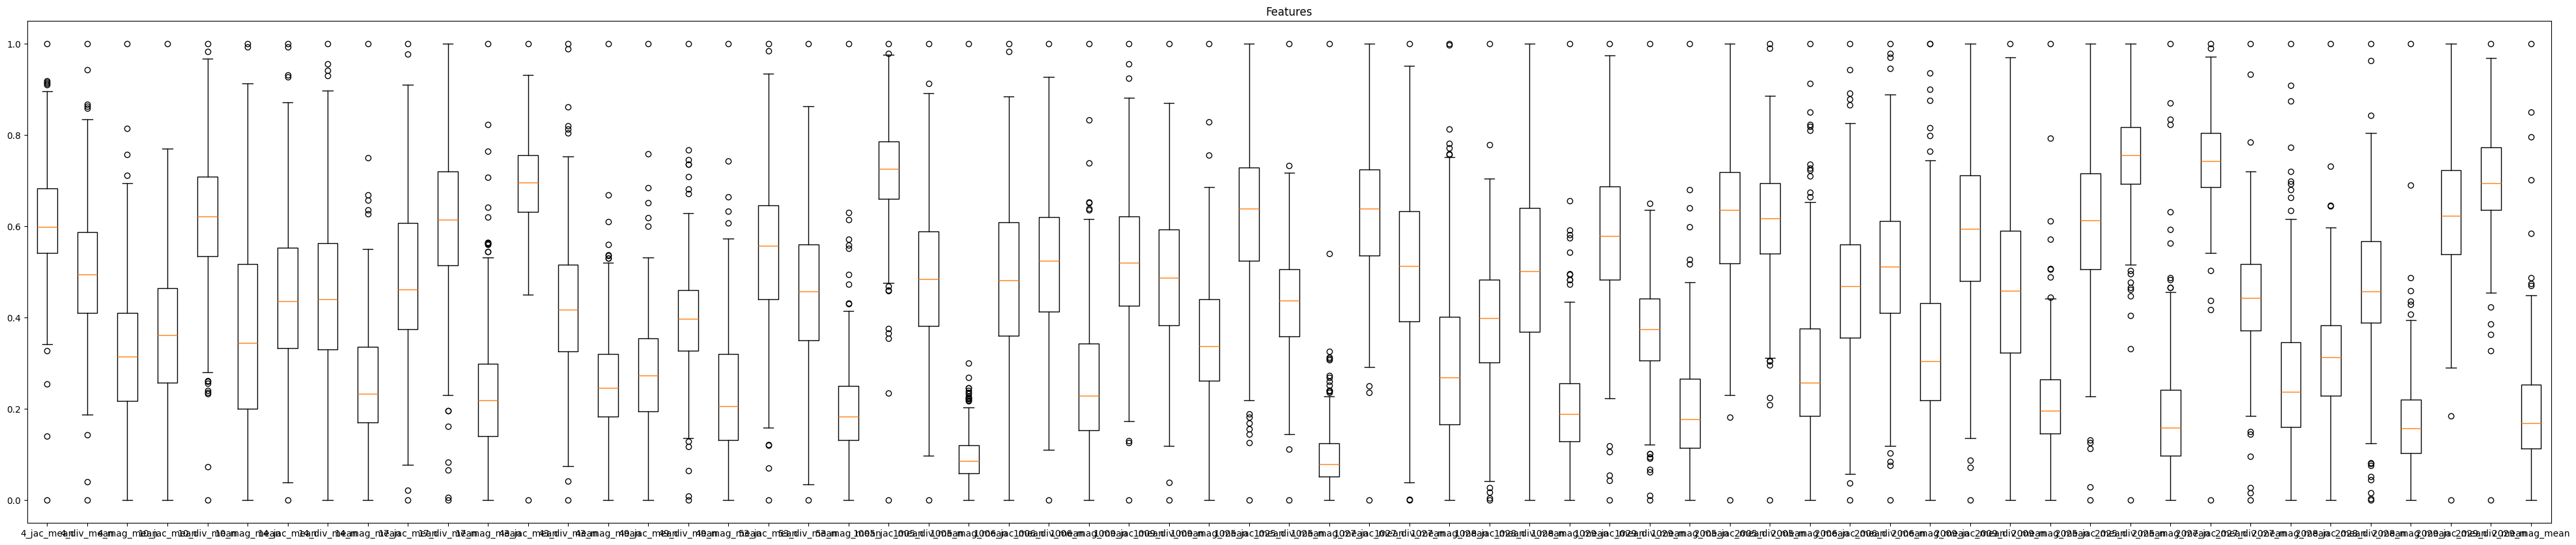

In [6]:
# Standardize each column
scaler = StandardScaler()
data_standardized = scaler.fit_transform(data)
data_standardized_df = pd.DataFrame(data_standardized, columns=data_columns)

# Normalize each column
normalizer = MinMaxScaler()
data_normalized = normalizer.fit_transform(data_standardized)
data_normalized_df = pd.DataFrame(data_normalized, columns=data_columns)

# visualize_voxplot(data_normalized, data_columns, nb_features=feat_per_tissue, nb_features_from=feat_per_tissue*1)
# visualize_voxplot(data_normalized, data_columns, nb_features=feat_per_tissue, nb_features_from=feat_per_tissue*2)

visualize_voxplot(data_normalized_df, data_columns, figsize=(50,10))


### Remove by correlation

In [7]:

corr_df = data_normalized_df.corr().abs()

mask = np.triu(np.ones_like(corr_df, dtype=bool))
tri_df = corr_df.mask(mask)

corr_th = 0.9
to_drop = [c for c in tri_df.columns if any(tri_df[c] > corr_th)]
print(to_drop)
# plot_correlation_heat_map_df(corr_df, data_normalized_df, figsize=(30, 30))


# # Suponiendo que la matriz de correlación se llama "correlation_matrix"
# indice_min = np.unravel_index(np.argmin(corr_df.values), corr_df.values.shape)
# print(corr_df.values)
# print("Índice del menor elemento:", indice_min)


[]


### PCA

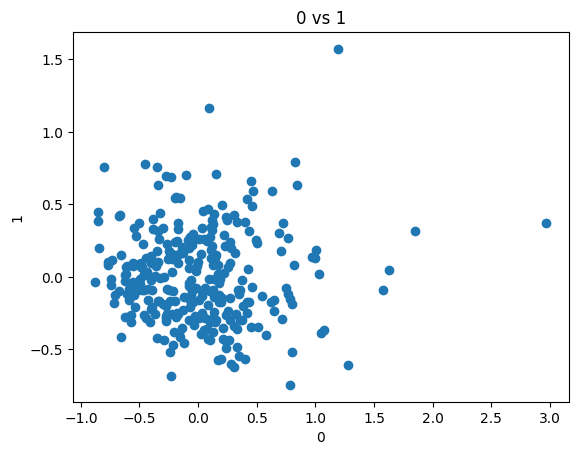

In [8]:
feat_pca = PCA(n_components=2)
res_pca = feat_pca.fit_transform(data_normalized_df)
plot_2v2(res_pca)

# Clustering

In [9]:
nb_clusters = 10
random_state = 42

def count_not_matching_clusters(clusters1, clusters2):
    count = 0
    for i in range(len(clusters1)):
        if clusters1[i] != clusters2[i]:
            count += 1
    return count

## K-means

In [10]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=nb_clusters, random_state=random_state)
clusters_kmeans = kmeans.fit_predict(data_normalized_df)
print(clusters_kmeans)



[7 5 1 0 5 2 6 6 0 9 0 4 3 8 7 0 9 0 4 2 3 7 8 1 0 5 0 1 0 1 2 3 8 3 4 2 7
 5 3 7 7 1 0 2 3 8 4 0 0 7 0 4 9 1 7 1 4 3 9 5 4 2 0 3 3 7 4 7 3 7 7 1 6 7
 0 7 1 4 1 0 5 3 0 5 6 6 3 1 7 7 2 2 8 0 0 3 0 0 3 0 0 1 4 0 8 8 4 1 0 0 5
 4 0 0 9 6 7 8 0 7 0 1 6 9 8 8 0 9 1 1 7 1 0 4 7 1 7 7 1 3 7 9 0 9 0 9 4 1
 7 0 3 7 3 5 0 2 1 8 7 2 7 7 7 7 0 0 6 4 9 5 0 7 0 0 2 0 0 5 0 1 8 6 0 4 3
 0 0 6 0 1 7 0 5 0 0 0 1 5 2 4 0 3 9 0 4 4 4 3 7 0 3 1 4 4 0 4 4 0 9 3 9 0
 0 9 0 7 0 0 9 3 0 4 1 1 0 0 0 7 7 3 7 4 0 1 0 4 9 1 3 3 0 8 0 1 4 1 6 7 6
 9 7 7 3 0 0 0 8 7 1 1 7 1 1 4 0 7 2 1 4 8 8 0 6 1 1 0 7 5 0 0 7 9 0 4 6 1
 7 6 5 4 5 6 1]


## EM

In [11]:
from sklearn.mixture import GaussianMixture

# Crear el objeto GaussianMixture
gmm = GaussianMixture(n_components=nb_clusters, random_state=random_state, init_params='kmeans', max_iter=10000, tol=1e-6)
clusters_em = gmm.fit_predict(data_normalized_df)
print(clusters_em)

count_not_matching_clusters(clusters_kmeans, clusters_em)


[7 5 1 0 5 2 6 6 0 9 0 4 3 8 7 0 9 0 4 2 3 7 8 1 0 5 0 1 0 1 2 3 8 3 4 2 7
 5 3 7 7 1 0 2 3 8 4 0 0 7 0 4 9 1 7 1 4 3 9 5 4 2 0 3 3 7 4 7 3 7 7 1 6 7
 0 7 1 4 1 0 5 3 0 5 6 6 3 1 7 7 2 2 8 0 0 3 0 0 3 0 0 1 4 0 8 8 4 1 0 0 5
 4 0 0 9 6 7 8 0 7 0 1 6 9 8 8 0 9 1 1 7 1 0 4 7 1 7 7 1 3 7 9 0 9 0 9 4 1
 7 0 3 7 3 5 0 2 1 8 7 2 7 7 7 7 0 0 6 4 9 5 0 7 0 0 2 0 0 5 0 1 8 6 0 4 3
 0 0 6 0 1 7 0 5 0 0 0 1 5 2 4 0 3 9 0 4 4 4 3 7 0 3 1 4 4 0 4 4 0 9 3 9 0
 0 9 0 7 0 0 9 3 0 4 1 1 0 0 0 7 7 3 7 4 0 1 0 4 9 1 3 3 0 8 0 1 4 1 6 7 6
 9 7 7 3 0 0 0 8 7 1 1 7 1 1 4 0 7 2 1 4 8 8 0 6 1 1 0 7 5 0 0 7 9 0 4 6 1
 7 6 5 4 5 6 1]


0

## Mean-shift

In [12]:
from sklearn.cluster import MeanShift


clustering = MeanShift()
clustering.fit(data_standardized_df)

# Obtener las etiquetas de los clusters y los centros de los clusters
clusters_mean_shift = clustering.labels_
print(len(np.unique(clusters_mean_shift)))
# cluster_centers = clustering.cluster_centers_
print(clusters_mean_shift)


13
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 12  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  9  0  0  0  0
  0  0  0  0  0  0  0  4  0  0  0  0  0  9  0  0  0  0  0  0  6  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0 11  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  8  0  0
  0  0  0  0  6  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  7  0  0  0  0  0  0  5  0  0  0  0  0 10  0  0  0  0  0  0  0  2
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  9  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  6  0  6  0  0  0  0  1  0  1  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  3  0  0  0  0  0  0  0  0]


## DBSCAN

In [13]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=7, min_samples=2)
dbscan.fit(data_standardized_df)
clusters_dbscan = dbscan.labels_

print(len(np.unique(clusters_dbscan)))
print(clusters_dbscan)

5
[-1 -1 -1 -1  0 -1 -1 -1 -1 -1  0 -1 -1 -1  0 -1  0  0 -1 -1 -1  0 -1  0
  0  1 -1  0  0 -1 -1  0 -1  0  0 -1 -1 -1 -1  0  0  0 -1 -1 -1  0  0  0
  0  0  0 -1 -1 -1  0 -1  0 -1  0 -1  0 -1 -1 -1  0 -1  0  0 -1 -1  0  0
 -1  0  0  0  0 -1 -1  0  0 -1  0 -1  0 -1 -1  0  0  0 -1 -1  0  0  0 -1
  0  0  0  0 -1 -1  0 -1 -1  2 -1 -1 -1  0 -1 -1 -1  0  0 -1  0 -1 -1  0
 -1 -1 -1 -1 -1 -1 -1 -1  0  0  0  0 -1 -1 -1  0  0 -1  0  0  0  0  0 -1
  0 -1 -1  0  0  0  0 -1 -1 -1 -1 -1 -1 -1  0 -1  0  0  0  0  0  0 -1 -1
  0  1  0  0  0  0 -1 -1 -1 -1 -1  0  0 -1  0 -1 -1  0  0  3  0  0  0 -1
 -1  0  0  0  0 -1 -1 -1  0 -1  0  0  0 -1 -1  0  0  0  0  0  0  0  0 -1
  0  0  0 -1  0  0  0 -1  0  0 -1  0 -1 -1 -1 -1  0  0  0  0  0  0  0  3
  0  0  0  0  0 -1  0  0  0 -1  0 -1  0 -1  0  0 -1 -1 -1  0  0  0  0 -1
  0  0 -1  0  0 -1  0 -1  0  0  0  0 -1 -1 -1 -1  2  0 -1 -1  0 -1  0 -1
  0  0  0  0 -1 -1 -1  0  0 -1 -1  0 -1 -1  0]


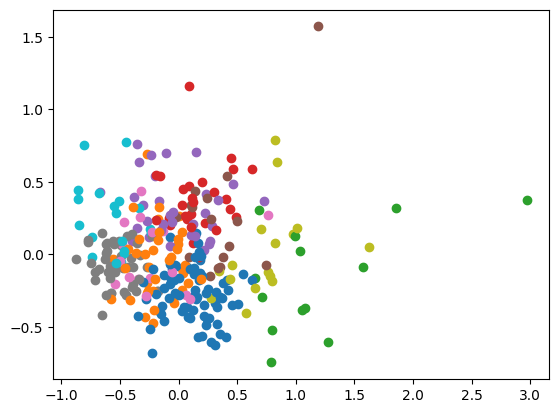

In [14]:
import matplotlib.pyplot as plt

# Obtener las coordenadas de los componentes principales
x = res_pca[:, 0]
y = res_pca[:, 1]

# Crear una figura y un conjunto de ejes
fig, ax = plt.subplots()

# Iterar sobre los elementos y asignar un color diferente a cada cluster
for i, cluster in enumerate(clusters_kmeans):
    # Obtener el color correspondiente al cluster
    color = 'C{}'.format(cluster)
    
    # Plotear el punto con el color correspondiente
    ax.scatter(x[i], y[i], color=color)

# Mostrar el gráfico
plt.show()
